In [1]:
from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

event_file = "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0"

scalars = defaultdict(list)

for raw in tf_record.tf_record_iterator(event_file):
    event = Event.FromString(raw)

    if not event.summary:
        continue

    for v in event.summary.value:
        if v.HasField("simple_value"):
            scalars[v.tag].append({
                "step": event.step,
                "value": v.simple_value,
                "wall_time": event.wall_time,
            })

print("Scalar tags found:")
for tag in scalars:
    print(tag)


2026-01-14 12:02:24.251243: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-14 12:02:24.281431: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-14 12:02:24.992259: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
Scalar tags found:
reward/total
action/index
action/sum
throughput/embb_mbps
throughput/urllc_mbps
latency/urllc
queues/embb_bytes
queues/urllc_bytes
prb/reserve_fraction
prb/effective_ratio
obs/embb_demand_prb
obs/urllc_demand_prb
obs/embb_throughput
obs/urllc_throughput
obs/embb_queue
obs/urllc_queue
obs/embb_base_achievable_throughput
obs/urllc_base_achievable_throughput
obs/reserve_used_prb
obs/effective_max_prb
state/embb_demand_norm
state/urllc_demand_norm
state/embb_queue_norm
state/urllc_queue_norm
state/embb_thr_norm
state/urllc_thr_norm
state/urllc_lat_excess_norm
state/effective_prb_ratio
state/reserve_used_norm
state/prev_action_e_norm
state/prev_action_u_norm
state/state_11
state/state_12
satisfaction/eMBB_capped
satisfaction/eMBB_raw
satisfaction/URLLC_capped
satisfaction/URLLC_raw
episode/return
episode/length


In [13]:
def tag_df(scalars, tag):
    d = pd.DataFrame(scalars[tag]).sort_values("step")
    return d[["step", "value"]].rename(columns={"value": tag})

# example: build a small merged table for one run
lat = tag_df(scalars, "latency/urllc")
embb = tag_df(scalars, "throughput/embb_mbps")
urllc = tag_df(scalars, "throughput/urllc_mbps")
prb = tag_df(scalars, "prb/effective_ratio")
res = tag_df(scalars, "prb/reserve_fraction")
sat_u = tag_df(scalars, "satisfaction/URLLC_capped")
sat_e = tag_df(scalars, "satisfaction/eMBB_capped")

run = lat.merge(prb, on="step", how="inner") \
         .merge(res, on="step", how="inner") \
         .merge(urllc, on="step", how="inner") \
         .merge(embb, on="step", how="inner") \
         .merge(sat_u, on="step", how="inner") \
         .merge(sat_e, on="step", how="inner")

run["jammed"] = run["prb/effective_ratio"] < 0.999
run.head()


,step,latency/urllc,prb/effective_ratio,prb/reserve_fraction,throughput/urllc_mbps,throughput/embb_mbps,satisfaction/URLLC_capped,satisfaction/eMBB_capped,jammed
0,10,0.0,0.975,0.0,41.599998,89.832001,1.0,0.584071,True
1,20,0.0,0.975,0.0,41.599998,89.447998,1.0,0.419048,True
2,30,0.0,0.975,0.0,41.599998,90.592003,1.0,0.330846,True
3,40,0.0,0.975,0.0,41.599998,89.279999,1.0,0.264646,True
4,50,0.0,0.975,0.0,41.599998,89.279999,1.0,0.223932,True


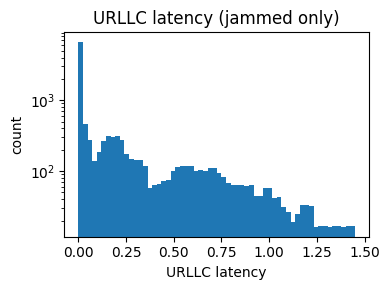

In [14]:
data = run[run["jammed"]]
plt.figure(figsize=(4,3))
plt.hist(data["latency/urllc"], bins=60)
plt.yscale("log")
plt.xlabel("URLLC latency")
plt.ylabel("count")
plt.title("URLLC latency (jammed only)")
plt.tight_layout()
plt.show()


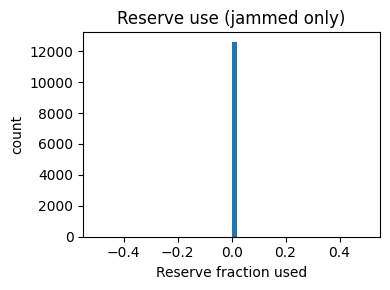

In [15]:
data = run[run["jammed"]]
plt.figure(figsize=(4,3))
plt.hist(data["prb/reserve_fraction"], bins=50)
plt.xlabel("Reserve fraction used")
plt.ylabel("count")
plt.title("Reserve use (jammed only)")
plt.tight_layout()
plt.show()


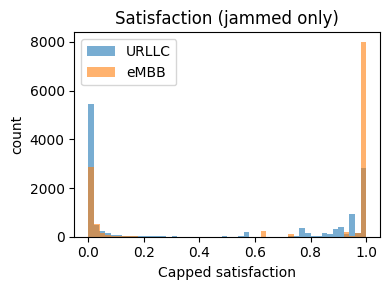

In [16]:
data = run[run["jammed"]]
plt.figure(figsize=(4,3))
plt.hist(data["satisfaction/URLLC_capped"], bins=50, alpha=0.6, label="URLLC")
plt.hist(data["satisfaction/eMBB_capped"], bins=50, alpha=0.6, label="eMBB")
plt.xlabel("Capped satisfaction")
plt.ylabel("count")
plt.title("Satisfaction (jammed only)")
plt.legend()
plt.tight_layout()
plt.show()


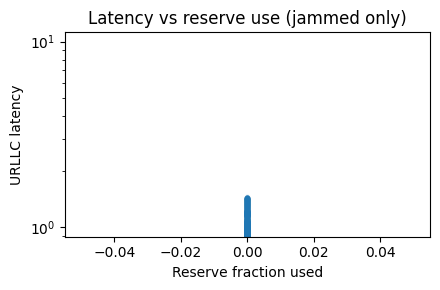

In [17]:
data = run[run["jammed"]]
plt.figure(figsize=(4.5,3))
plt.scatter(data["prb/reserve_fraction"], data["latency/urllc"], alpha=0.2, s=10)
plt.yscale("log")
plt.xlabel("Reserve fraction used")
plt.ylabel("URLLC latency")
plt.title("Latency vs reserve use (jammed only)")
plt.tight_layout()
plt.show()


Loaded scalar tags:
   reward/total
   action/index
   action/sum
   throughput/embb_mbps
   throughput/urllc_mbps
   latency/urllc
   queues/embb_bytes
   queues/urllc_bytes
   prb/reserve_fraction
   prb/effective_ratio
   obs/embb_demand_prb
   obs/urllc_demand_prb
   obs/embb_throughput
   obs/urllc_throughput
   obs/embb_queue
   obs/urllc_queue
   obs/embb_base_achievable_throughput
   obs/urllc_base_achievable_throughput
   obs/reserve_used_prb
   obs/effective_max_prb
   state/embb_demand_norm
   state/urllc_demand_norm
   state/embb_queue_norm
   state/urllc_queue_norm
   state/embb_thr_norm
   state/urllc_thr_norm
   state/urllc_lat_excess_norm
   state/effective_prb_ratio
   state/reserve_used_norm
   state/prev_action_e_norm
   state/prev_action_u_norm
   state/state_11
   state/state_12
   satisfaction/eMBB_capped
   satisfaction/eMBB_raw
   satisfaction/URLLC_capped
   satisfaction/URLLC_raw
   episode/return
   episode/length
Detected 63 jamming start events
Usable align

/tmp/ipykernel_565250/1531084528.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))


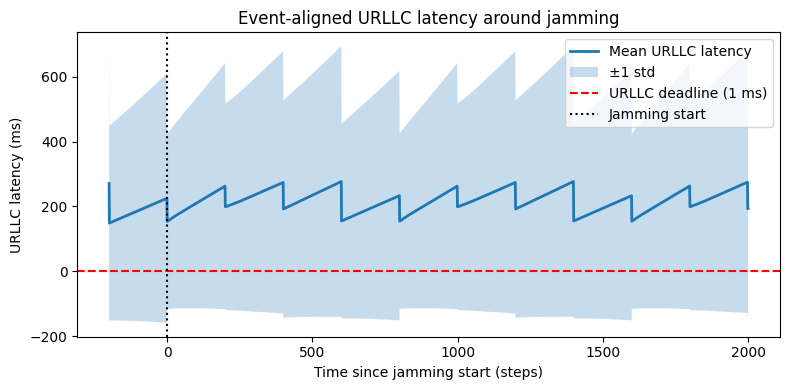

In [6]:
# ============================================================
# 0. Imports
# ============================================================

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict


# ============================================================
# 1. Load TensorBoard event file
# ============================================================

# event_file = (
#     "../tb_logs/res_validator/"
#     "idle__20260113_104214__res18_off0_const5_per8000_dur2000/"
#     "events.out.tfevents.1768318934.elahe-LEGION-T7-34IAS10.492429.0"
# )

event_file = "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0"


scalars = defaultdict(list)

for raw in tf_record.tf_record_iterator(event_file):
    event = Event.FromString(raw)

    if not event.summary:
        continue

    for v in event.summary.value:
        if v.HasField("simple_value"):
            scalars[v.tag].append({
                "step": event.step,
                "value": v.simple_value,
                "wall_time": event.wall_time,
            })

print("Loaded scalar tags:")
for k in scalars:
    print("  ", k)


# ============================================================
# 2. Build pandas DataFrames for latency and PRB ratio
# ============================================================

lat = (
    pd.DataFrame(scalars["latency/urllc"])
    .sort_values("step")
    .reset_index(drop=True)
)

prb = (
    pd.DataFrame(scalars["prb/effective_ratio"])
    .sort_values("step")
    .reset_index(drop=True)
)


# ============================================================
# 3. Merge latency and PRB data (step-aligned)
# ============================================================

# df = pd.merge_asof(
#     lat,
#     prb,
#     on="step",
#     direction="nearest",
#     tolerance=5,  # small tolerance in steps
# )

# df.columns = ["step", "latency_sec", "wall_time", "effective_prb_ratio"]
# df = df.dropna().reset_index(drop=True)

df = pd.merge_asof(
    lat,
    prb,
    on="step",
    direction="nearest",
    tolerance=5,
    suffixes=("_lat", "_prb")
)

# rename explicitly
df = df.rename(columns={
    "value_lat": "latency_sec",
    "value_prb": "effective_prb_ratio",
})

# keep only what we need
df = df[["step", "latency_sec", "effective_prb_ratio"]]

df = df.dropna().reset_index(drop=True)


# define jamming
df["jammed"] = df["effective_prb_ratio"] < 0.999


# ============================================================
# 4. Detect jamming start events
# ============================================================

jam_start_indices = df.index[
    (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
].to_numpy()

print(f"Detected {len(jam_start_indices)} jamming start events")


# ============================================================
# 5. Extract event-aligned latency windows
# ============================================================

PRE_STEPS  = 200    # steps before jamming
POST_STEPS = 2000   # steps after jamming

aligned_windows = []

for idx in jam_start_indices:
    start = idx - PRE_STEPS
    end   = idx + POST_STEPS

    if start < 0 or end >= len(df):
        continue

    window = df.iloc[start:end].copy()
    window["t_rel"] = np.arange(-PRE_STEPS, POST_STEPS)
    aligned_windows.append(window[["t_rel", "latency_sec"]])

print(f"Usable aligned events: {len(aligned_windows)}")


# ============================================================
# 6. Aggregate across events
# ============================================================

aligned_df = pd.concat(aligned_windows, ignore_index=True)

summary = (
    aligned_df
    .groupby("t_rel")["latency_sec"]
    .agg(mean="mean", std="std")
    .reset_index()
)

# convert to milliseconds
summary["mean_ms"] = summary["mean"] * 1000.0
summary["std_ms"]  = summary["std"]  * 1000.0


# ============================================================
# 7. Plot: Event-aligned URLLC latency (downgrade → recovery)
# ============================================================

URLLC_DEADLINE_MS = 1.0  # 1 ms

plt.figure(figsize=(8, 4))

plt.plot(
    summary["t_rel"],
    summary["mean_ms"],
    linewidth=2,
    label="Mean URLLC latency"
)

plt.fill_between(
    summary["t_rel"],
    summary["mean_ms"] - summary["std_ms"],
    summary["mean_ms"] + summary["std_ms"],
    alpha=0.25,
    label="±1 std"
)

plt.axhline(
    URLLC_DEADLINE_MS,
    color="red",
    linestyle="--",
    label="URLLC deadline (1 ms)"
)

plt.axvline(
    0,
    color="black",
    linestyle=":",
    label="Jamming start"
)

plt.xlabel("Time since jamming start (steps)")
plt.ylabel("URLLC latency (ms)")
plt.title("Event-aligned URLLC latency around jamming")
plt.legend()
plt.tight_layout()
plt.show()


Loaded scalar tags:
   reward/total
   action/index
   action/sum
   throughput/embb_mbps
   throughput/urllc_mbps
   latency/urllc
   queues/embb_bytes
   queues/urllc_bytes
   prb/reserve_fraction
   prb/effective_ratio
   obs/embb_demand_prb
   obs/urllc_demand_prb
   obs/embb_throughput
   obs/urllc_throughput
   obs/embb_queue
   obs/urllc_queue
   obs/embb_base_achievable_throughput
   obs/urllc_base_achievable_throughput
   obs/reserve_used_prb
   obs/effective_max_prb
   state/embb_demand_norm
   state/urllc_demand_norm
   state/embb_queue_norm
   state/urllc_queue_norm
   state/embb_thr_norm
   state/urllc_thr_norm
   state/urllc_lat_excess_norm
   state/effective_prb_ratio
   state/reserve_used_norm
   state/prev_action_e_norm
   state/prev_action_u_norm
   state/state_11
   state/state_12
   satisfaction/eMBB_capped
   satisfaction/eMBB_raw
   satisfaction/URLLC_capped
   satisfaction/URLLC_raw
   episode/return
   episode/length
Detected 63 jamming start events
Usable align

/tmp/ipykernel_565250/607325484.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))


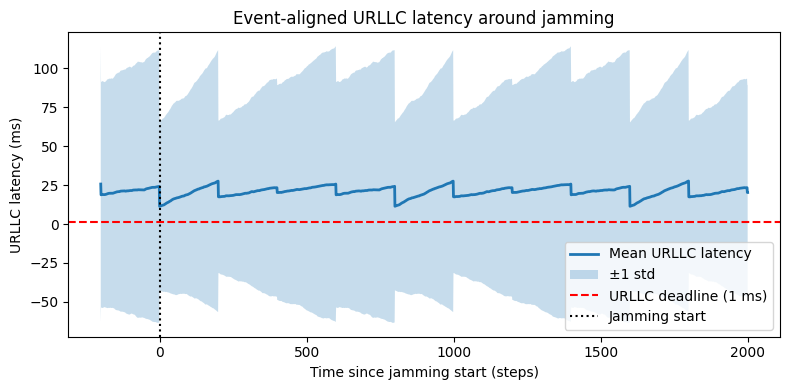

In [7]:
# ============================================================
# 0. Imports
# ============================================================

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict


# ============================================================
# 1. Load TensorBoard event file
# ============================================================

# event_file = (
#     "../tb_logs/res_validator/"
#     "idle__20260113_104214__res18_off0_const5_per8000_dur2000/"
#     "events.out.tfevents.1768318934.elahe-LEGION-T7-34IAS10.492429.0"
# )

event_file = "../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0"


scalars = defaultdict(list)

for raw in tf_record.tf_record_iterator(event_file):
    event = Event.FromString(raw)

    if not event.summary:
        continue

    for v in event.summary.value:
        if v.HasField("simple_value"):
            scalars[v.tag].append({
                "step": event.step,
                "value": v.simple_value,
                "wall_time": event.wall_time,
            })

print("Loaded scalar tags:")
for k in scalars:
    print("  ", k)


# ============================================================
# 2. Build pandas DataFrames for latency and PRB ratio
# ============================================================

lat = (
    pd.DataFrame(scalars["latency/urllc"])
    .sort_values("step")
    .reset_index(drop=True)
)

prb = (
    pd.DataFrame(scalars["prb/effective_ratio"])
    .sort_values("step")
    .reset_index(drop=True)
)


# ============================================================
# 3. Merge latency and PRB data (step-aligned)
# ============================================================

# df = pd.merge_asof(
#     lat,
#     prb,
#     on="step",
#     direction="nearest",
#     tolerance=5,  # small tolerance in steps
# )

# df.columns = ["step", "latency_sec", "wall_time", "effective_prb_ratio"]
# df = df.dropna().reset_index(drop=True)

df = pd.merge_asof(
    lat,
    prb,
    on="step",
    direction="nearest",
    tolerance=5,
    suffixes=("_lat", "_prb")
)

# rename explicitly
df = df.rename(columns={
    "value_lat": "latency_sec",
    "value_prb": "effective_prb_ratio",
})

# keep only what we need
df = df[["step", "latency_sec", "effective_prb_ratio"]]

df = df.dropna().reset_index(drop=True)


# define jamming
df["jammed"] = df["effective_prb_ratio"] < 0.999


# ============================================================
# 4. Detect jamming start events
# ============================================================

jam_start_indices = df.index[
    (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
].to_numpy()

print(f"Detected {len(jam_start_indices)} jamming start events")


# ============================================================
# 5. Extract event-aligned latency windows
# ============================================================

PRE_STEPS  = 200    # steps before jamming
POST_STEPS = 2000   # steps after jamming

aligned_windows = []

for idx in jam_start_indices:
    start = idx - PRE_STEPS
    end   = idx + POST_STEPS

    if start < 0 or end >= len(df):
        continue

    window = df.iloc[start:end].copy()
    window["t_rel"] = np.arange(-PRE_STEPS, POST_STEPS)
    aligned_windows.append(window[["t_rel", "latency_sec"]])

print(f"Usable aligned events: {len(aligned_windows)}")


# ============================================================
# 6. Aggregate across events
# ============================================================

aligned_df = pd.concat(aligned_windows, ignore_index=True)

summary = (
    aligned_df
    .groupby("t_rel")["latency_sec"]
    .agg(mean="mean", std="std")
    .reset_index()
)

# convert to milliseconds
summary["mean_ms"] = summary["mean"] * 1000.0
summary["std_ms"]  = summary["std"]  * 1000.0


# ============================================================
# 7. Plot: Event-aligned URLLC latency (downgrade → recovery)
# ============================================================

URLLC_DEADLINE_MS = 1.0  # 1 ms

plt.figure(figsize=(8, 4))

plt.plot(
    summary["t_rel"],
    summary["mean_ms"],
    linewidth=2,
    label="Mean URLLC latency"
)

plt.fill_between(
    summary["t_rel"],
    summary["mean_ms"] - summary["std_ms"],
    summary["mean_ms"] + summary["std_ms"],
    alpha=0.25,
    label="±1 std"
)

plt.axhline(
    URLLC_DEADLINE_MS,
    color="red",
    linestyle="--",
    label="URLLC deadline (1 ms)"
)

plt.axvline(
    0,
    color="black",
    linestyle=":",
    label="Jamming start"
)

plt.xlabel("Time since jamming start (steps)")
plt.ylabel("URLLC latency (ms)")
plt.title("Event-aligned URLLC latency around jamming")
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
def event_aligned_latency_summary(event_file,
                                  pre_steps=200,
                                  post_steps=2000,
                                  jam_threshold=0.999):
    from tensorflow.python.lib.io import tf_record
    from tensorboard.compat.proto.event_pb2 import Event
    from collections import defaultdict
    import pandas as pd
    import numpy as np

    scalars = defaultdict(list)

    for raw in tf_record.tf_record_iterator(event_file):
        event = Event.FromString(raw)
        if not event.summary:
            continue
        for v in event.summary.value:
            if v.HasField("simple_value"):
                scalars[v.tag].append({
                    "step": event.step,
                    "value": v.simple_value,
                })

    lat = pd.DataFrame(scalars["latency/urllc"]).sort_values("step")
    prb = pd.DataFrame(scalars["prb/effective_ratio"]).sort_values("step")

    df = pd.merge_asof(
        lat, prb,
        on="step",
        direction="nearest",
        tolerance=5,
        suffixes=("_lat", "_prb")
    ).dropna()

    df = df.rename(columns={
        "value_lat": "latency_sec",
        "value_prb": "effective_prb_ratio"
    })

    df["jammed"] = df["effective_prb_ratio"] < jam_threshold

    jam_start_idx = df.index[
        (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
    ].to_numpy()

    aligned = []

    for idx in jam_start_idx:
        s = idx - pre_steps
        e = idx + post_steps
        if s < 0 or e >= len(df):
            continue
        w = df.iloc[s:e].copy()
        w["t_rel"] = np.arange(-pre_steps, post_steps)
        aligned.append(w[["t_rel", "latency_sec"]])

    aligned_df = pd.concat(aligned)

    summary = (
        aligned_df
        .groupby("t_rel")["latency_sec"]
        .mean()
        .reset_index()
    )

    summary["latency_ms"] = summary["latency_sec"] * 1000.0
    return summary


In [10]:
IDLE_EVENT_FILE = "../tb_logs/res_validator/idle__20260114_104940__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768405780.elahe-LEGION-T7-34IAS10.557366.0"
RANDOM_EVENT_FILE = "../tb_logs/res_validator/random__20260114_103447__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768404887.elahe-LEGION-T7-34IAS10.555124.0"
#DQN_EVENT_FILE = "../tb_logs/res_validator/dqn__20260114_133939__res18_off0_const5_per8000_dur2000/events.out.tfevents.1768423979.elahe-LEGION-T7-34IAS10.599999.0"
idle_summary   = event_aligned_latency_summary(IDLE_EVENT_FILE)
random_summary = event_aligned_latency_summary(RANDOM_EVENT_FILE)
#dqn_summary    = event_aligned_latency_summary(DQN_EVENT_FILE)


/tmp/ipykernel_565250/2481062412.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_565250/2481062412.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))


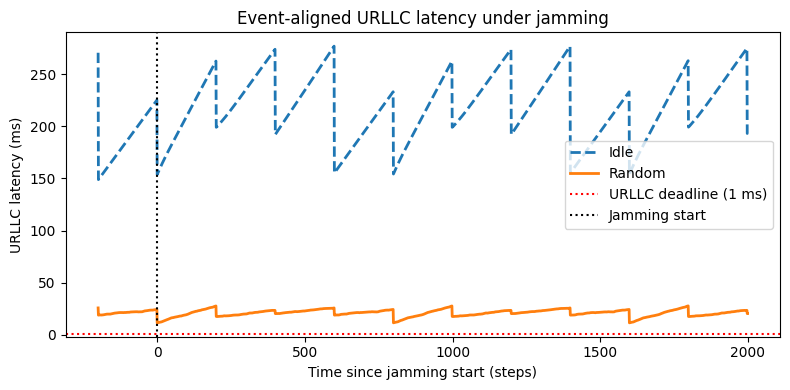

In [12]:
URLLC_DEADLINE_MS = 1.0

plt.figure(figsize=(8, 4))

plt.plot(idle_summary["t_rel"],
         idle_summary["latency_ms"],
         label="Idle",
         linewidth=2,
         linestyle="--")

plt.plot(random_summary["t_rel"],
         random_summary["latency_ms"],
         label="Random",
         linewidth=2)

# plt.plot(dqn_summary["t_rel"],
#          dqn_summary["latency_ms"],
#          label="DQN",
#          linewidth=2)

plt.axhline(URLLC_DEADLINE_MS,
            color="red",
            linestyle=":",
            label="URLLC deadline (1 ms)")

plt.axvline(0,
            color="black",
            linestyle=":",
            label="Jamming start")

plt.xlabel("Time since jamming start (steps)")
plt.ylabel("URLLC latency (ms)")
plt.title("Event-aligned URLLC latency under jamming")
plt.legend()
plt.tight_layout()
plt.show()


In [15]:
idle_summary = event_aligned_latency_summary(
    event_file=IDLE_EVENT_FILE
)

random_summary = event_aligned_latency_summary(
    event_file=RANDOM_EVENT_FILE
)

# dqn_summary = event_aligned_latency_summary(
#     event_file=DQN_EVENT_FILE
# )


/tmp/ipykernel_565250/2481062412.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_565250/2481062412.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))


In [17]:
from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event
from collections import defaultdict
import pandas as pd
import numpy as np

def load_scalars(event_file):
    scalars = defaultdict(list)
    for raw in tf_record.tf_record_iterator(event_file):
        event = Event.FromString(raw)
        if not event.summary:
            continue
        for v in event.summary.value:
            if v.HasField("simple_value"):
                scalars[v.tag].append({
                    "step": event.step,
                    "value": v.simple_value,
                })
    return scalars


def event_aligned_metric(
    event_file,
    metric_tag,
    pre_steps=200,
    post_steps=2000,
    jam_threshold=0.999,
):
    """
    Generic event-aligned extractor for any scalar metric
    """

    scalars = load_scalars(event_file)

    metric = pd.DataFrame(scalars[metric_tag]).sort_values("step")
    prb = pd.DataFrame(scalars["prb/effective_ratio"]).sort_values("step")

    df = pd.merge_asof(
        metric, prb,
        on="step",
        direction="nearest",
        tolerance=5,
        suffixes=("_m", "_prb"),
    ).dropna()

    df = df.rename(columns={
        "value_m": "metric",
        "value_prb": "effective_prb_ratio",
    })

    df["jammed"] = df["effective_prb_ratio"] < jam_threshold

    jam_start_idx = df.index[
        (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
    ].to_numpy()

    aligned = []

    for idx in jam_start_idx:
        s = idx - pre_steps
        e = idx + post_steps
        if s < 0 or e >= len(df):
            continue
        w = df.iloc[s:e].copy()
        w["t_rel"] = np.arange(-pre_steps, post_steps)
        aligned.append(w[["t_rel", "metric"]])

    aligned_df = pd.concat(aligned, ignore_index=True)

    summary = (
        aligned_df
        .groupby("t_rel")["metric"]
        .agg(mean="mean", std="std")
        .reset_index()
    )

    return summary


/tmp/ipykernel_565250/2735486263.py:54: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_565250/2735486263.py:54: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))


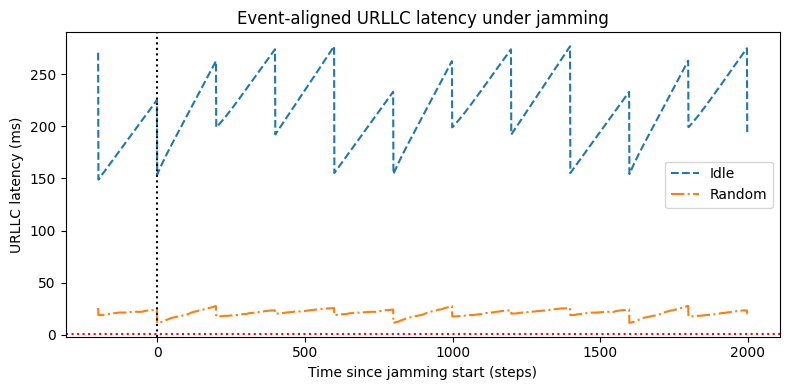

In [21]:
import matplotlib.pyplot as plt

URLLC_DEADLINE_MS = 1.0

idle_lat = event_aligned_metric(IDLE_EVENT_FILE, "latency/urllc")
rnd_lat  = event_aligned_metric(RANDOM_EVENT_FILE, "latency/urllc")
#  = event_aligned_metric(DQN_EVENT_FILE, "latency/urllc")

# convert to ms
#for df in [idle_lat, rnd_lat, dqn_lat]:
for df in [idle_lat, rnd_lat]:
    df["mean_ms"] = df["mean"] * 1000
    df["std_ms"]  = df["std"]  * 1000

plt.figure(figsize=(8,4))

plt.plot(idle_lat.t_rel, idle_lat.mean_ms, "--", label="Idle")
plt.plot(rnd_lat.t_rel,  rnd_lat.mean_ms,  "-.", label="Random")
# plt.plot(dqn_lat.t_rel,  dqn_lat.mean_ms,  label="DQN", linewidth=2.5)

# lower = (dqn_lat.mean_ms - dqn_lat.std_ms).clip(lower=0)
# upper = dqn_lat.mean_ms + dqn_lat.std_ms

#plt.fill_between(dqn_lat.t_rel, lower, upper, alpha=0.25)

plt.axhline(URLLC_DEADLINE_MS, color="red", linestyle=":")
plt.axvline(0, color="black", linestyle=":")

plt.xlabel("Time since jamming start (steps)")
plt.ylabel("URLLC latency (ms)")
plt.title("Event-aligned URLLC latency under jamming")
plt.legend()
plt.tight_layout()
plt.show()


/tmp/ipykernel_565250/2735486263.py:54: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))
/tmp/ipykernel_565250/2735486263.py:54: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  (df["jammed"]) & (~df["jammed"].shift(1).fillna(False))


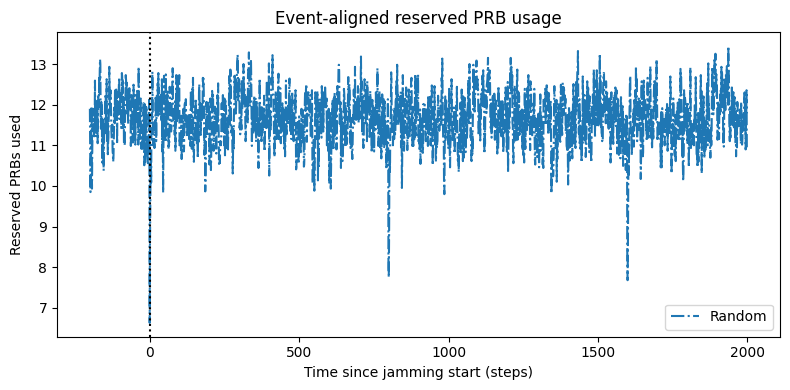

In [26]:
idle_prb = event_aligned_metric(IDLE_EVENT_FILE, "obs/reserve_used_prb")
rnd_prb  = event_aligned_metric(RANDOM_EVENT_FILE, "obs/reserve_used_prb")
#dqn_prb  = event_aligned_metric(DQN_EVENT_FILE, "obs/reserve_used_prb")

plt.figure(figsize=(8,4))

#plt.plot(rnd_prb.t_rel, rnd_prb.mean, "-.", label="Random")
plt.plot(
    rnd_prb["t_rel"],
    rnd_prb["mean"],
    "-.",
    label="Random"
)

# plt.plot(dqn_prb.t_rel, dqn_prb.mean, label="DQN", linewidth=2.5)

# lower = (dqn_prb.mean - dqn_prb.std).clip(lower=0)
# upper = dqn_prb.mean + dqn_prb.std
# plt.fill_between(dqn_prb.t_rel, lower, upper, alpha=0.25)

plt.axvline(0, color="black", linestyle=":")

plt.xlabel("Time since jamming start (steps)")
plt.ylabel("Reserved PRBs used")
plt.title("Event-aligned reserved PRB usage")
plt.legend()
plt.tight_layout()
plt.show()


In [34]:
import numpy as np

def recovery_time_from_mean(summary, threshold_ms=1, hold_steps=10):
    """
    Returns recovery time (t_rel) if recovered,
    otherwise returns np.nan
    """

    below = summary["mean_ms"] <= threshold_ms
    print(summary['mean_ms'])

    # rolling window to enforce consecutive condition
    sustained = below.rolling(hold_steps).sum() >= hold_steps

    if not sustained.any():
        return np.nan  # no recovery

    return summary.loc[sustained.idxmax(), "t_rel"]


In [35]:
methods = {
    "Idle": idle_lat,
    "Random": rnd_lat,
    # "DQN": dqn_lat,
}

recovery = {
    name: recovery_time_from_mean(df)
    for name, df in methods.items()
}

print(recovery)


0       270.642648
1       148.887386
2       149.267106
3       149.651311
4       150.035066
           ...    
2195    274.159874
2196    274.557568
2197    274.954099
2198    193.192860
2199    193.627159
Name: mean_ms, Length: 2200, dtype: float64
0       25.703538
1       18.802120
2       18.810286
3       18.874434
4       18.923510
          ...    
2195    23.356625
2196    23.363454
2197    23.347622
2198    20.253628
2199    20.270543
Name: mean_ms, Length: 2200, dtype: float64
{'Idle': nan, 'Random': nan}


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

lat = pd.DataFrame(scalars["latency/urllc"]).sort_values("step")
prb = pd.DataFrame(scalars["prb/effective_ratio"]).sort_values("step")


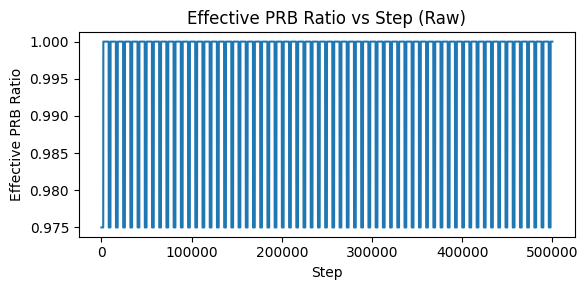

In [4]:
prb = pd.DataFrame(scalars["prb/effective_ratio"])

plt.figure(figsize=(6, 3))
plt.plot(prb["step"], prb["value"])
plt.xlabel("Step")
plt.ylabel("Effective PRB Ratio")
plt.title("Effective PRB Ratio vs Step (Raw)")
plt.tight_layout()
plt.show()


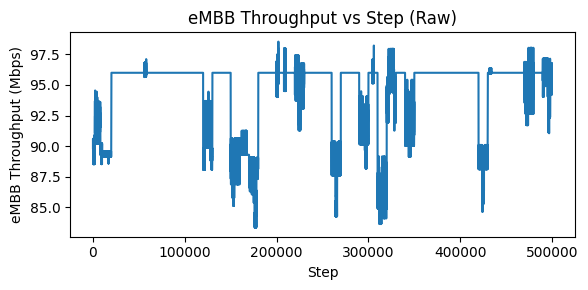

In [5]:
embb = pd.DataFrame(scalars["throughput/embb_mbps"])

plt.figure(figsize=(6, 3))
plt.plot(embb["step"], embb["value"])
plt.xlabel("Step")
plt.ylabel("eMBB Throughput (Mbps)")
plt.title("eMBB Throughput vs Step (Raw)")
plt.tight_layout()
plt.show()


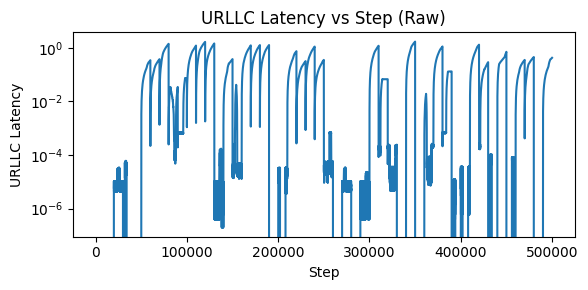

In [6]:
lat = pd.DataFrame(scalars["latency/urllc"])

plt.figure(figsize=(6, 3))
plt.plot(lat["step"], lat["value"])
plt.xlabel("Step")
plt.ylabel("URLLC Latency")
plt.yscale("log")
plt.title("URLLC Latency vs Step (Raw)")
plt.tight_layout()
plt.show()


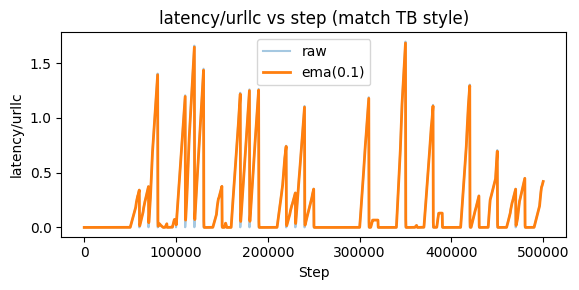

In [7]:
lat = pd.DataFrame(scalars["latency/urllc"]).sort_values("step")

plt.figure(figsize=(6,3))
plt.plot(lat["step"], lat["value"], alpha=0.4, label="raw")

# optional: emulate TensorBoard smoothing (EMA-ish)
lat["ema"] = lat["value"].ewm(alpha=0.1, adjust=False).mean()
plt.plot(lat["step"], lat["ema"], linewidth=2, label="ema(0.1)")

plt.xlabel("Step")
plt.ylabel("latency/urllc")
plt.title("latency/urllc vs step (match TB style)")
plt.legend()
plt.tight_layout()
plt.show()


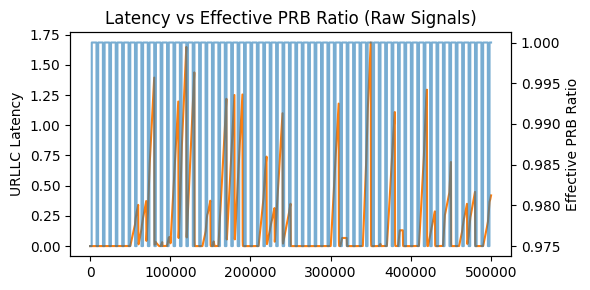

In [8]:
lat = pd.DataFrame(scalars["latency/urllc"]).sort_values("step")
prb = pd.DataFrame(scalars["prb/effective_ratio"]).sort_values("step")

plt.figure(figsize=(6, 3))

# latency (left axis)
plt.plot(lat["step"], lat["value"].ewm(alpha=0.1, adjust=False).mean(),
         label="URLLC Latency (EMA)", color="tab:orange")

plt.ylabel("URLLC Latency")

# PRB ratio (right axis)
ax2 = plt.gca().twinx()
ax2.plot(prb["step"], prb["value"],
         label="Effective PRB Ratio", color="tab:blue", alpha=0.6)
ax2.set_ylabel("Effective PRB Ratio")

plt.xlabel("Step")
plt.title("Latency vs Effective PRB Ratio (Raw Signals)")
plt.tight_layout()
plt.show()


In [9]:
lat = pd.DataFrame(scalars["latency/urllc"])
prb = pd.DataFrame(scalars["prb/effective_ratio"])

# merge by nearest step (safe because both are monotonic)
merged = pd.merge_asof(
    lat.sort_values("step"),
    prb.sort_values("step"),
    on="step",
    direction="nearest",
    tolerance=5  # small tolerance in steps
)

merged = merged.dropna()
merged.head()


,step,value_x,wall_time_x,value_y,wall_time_y
0,10,0.0,1.768406e+09,0.975,1.768406e+09
1,20,0.0,1.768406e+09,0.975,1.768406e+09
2,30,0.0,1.768406e+09,0.975,1.768406e+09
3,40,0.0,1.768406e+09,0.975,1.768406e+09
4,50,0.0,1.768406e+09,0.975,1.768406e+09


In [10]:
merged["jammed"] = merged["value_y"] < 0.999
merged.rename(columns={
    "value_x": "latency",
    "value_y": "effective_prb_ratio"
}, inplace=True)


<Figure size 400x300 with 0 Axes>

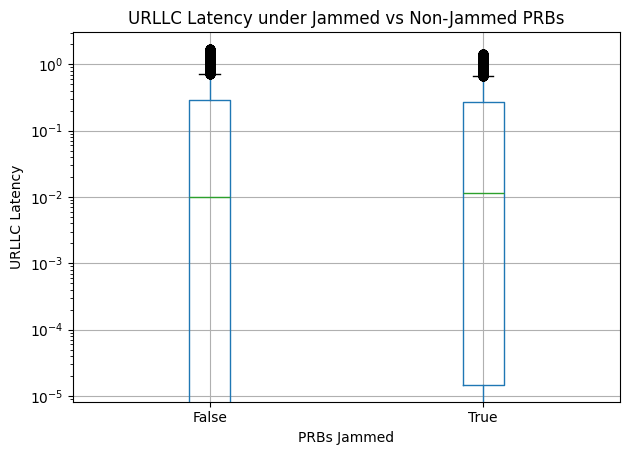

In [11]:
plt.figure(figsize=(4, 3))
merged.boxplot(column="latency", by="jammed")
plt.yscale("log")
plt.suptitle("")
plt.title("URLLC Latency under Jammed vs Non-Jammed PRBs")
plt.xlabel("PRBs Jammed")
plt.ylabel("URLLC Latency")
plt.tight_layout()
plt.show()


In [6]:
lat = pd.DataFrame(scalars["latency/urllc"])

print("min step:", lat["step"].min(), "max step:", lat["step"].max())
print("num points:", len(lat))
print("unique steps:", lat["step"].nunique())

# how many duplicated steps?
dup = len(lat) - lat["step"].nunique()
print("duplicate step entries:", dup)

# always sort before plotting
lat = lat.sort_values("step")


min step: 10 max step: 499990
num points: 49950
unique steps: 49950
duplicate step entries: 0


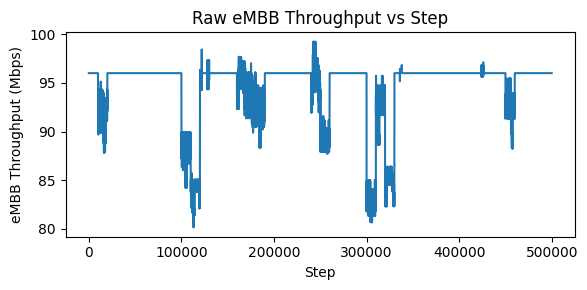

In [ ]:
embb = df[df["tag"] == "throughput/embb_mbps"]

plt.figure(figsize=(6, 3))
plt.plot(embb["step"], embb["value"])
plt.xlabel("Step")
plt.ylabel("eMBB Throughput (Mbps)")
plt.title("Raw eMBB Throughput vs Step")
plt.tight_layout()
plt.show()



In [2]:
rows = []
for tag, values in scalars.items():
    for v in values:
        rows.append({
            "tag": tag,
            "step": int(v["step"]),
            "value": v["value"],
        })

df = pd.DataFrame(rows)
df = df.sort_values("step").reset_index(drop=True)

df.head()


,tag,step,value
0,episode/length,0,9.990000e+02
1,episode/return,0,0.000000e+00
2,episode/return,1,4.026712e+09
3,episode/length,1,9.990000e+02
4,episode/length,2,9.990000e+02


In [3]:
wide = df.pivot_table(
    index="step",
    columns="tag",
    values="value",
    aggfunc="last"
).reset_index()

wide.head()


tag,step,action/index,action/sum,episode/length,episode/return,latency/urllc,obs/effective_max_prb,obs/embb_base_achievable_throughput,obs/embb_demand_prb,obs/embb_queue,...,state/prev_action_u_norm,state/reserve_used_norm,state/state_11,state/state_12,state/urllc_demand_norm,state/urllc_lat_excess_norm,state/urllc_queue_norm,state/urllc_thr_norm,throughput/embb_mbps,throughput/urllc_mbps
0,0,NaN,NaN,999.0,0.000000e+00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,NaN,999.0,4.026712e+09,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,999.0,-5.783739e+02,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,999.0,0.000000e+00,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,NaN,NaN,999.0,-1.500655e+02,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
wide["jamming"] = wide["prb/effective_ratio"] < 0.999
wide["jammed_fraction"] = 1.0 - wide["prb/effective_ratio"]
wide["jamming"].value_counts()

jamming
False    37409
True     12587
Name: count, dtype: int64

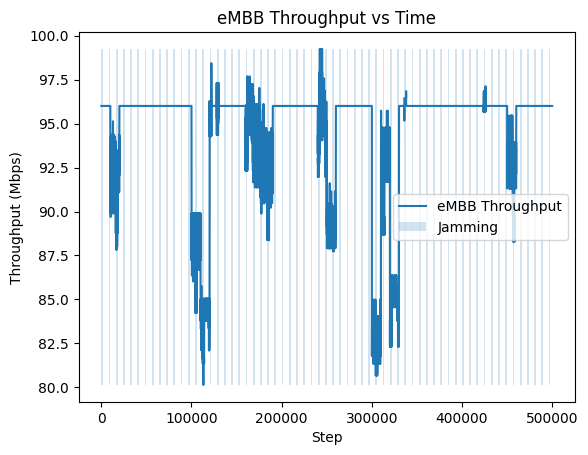

In [ ]:


plt.figure()
plt.plot(wide["step"], wide["throughput/embb_mbps"], label="eMBB Throughput")

# shade jamming periods
plt.fill_between(
    wide["step"],
    wide["throughput/embb_mbps"].min(),
    wide["throughput/embb_mbps"].max(),
    where=wide["jamming"],
    alpha=0.2,
    label="Jamming"
)

plt.xlabel("Step")
plt.ylabel("Throughput (Mbps)")
plt.legend()
plt.title("eMBB Throughput vs Time")
plt.show()


In [12]:
wide["episode"] = (wide["episode/length"].notna()).cumsum()

In [13]:
episodes_per_plot = 10

ep_ids = wide["episode"].unique()

for i in range(0, len(ep_ids), episodes_per_plot):
    ep_chunk = ep_ids[i:i+episodes_per_plot]
    chunk_df = wide[wide["episode"].isin(ep_chunk)]

    # plot here


In [14]:
wide["episode"].nunique()


50

In [15]:
wide.groupby("episode")["step"].count().head()


episode
1    1
2    1
3    1
4    1
5    1
Name: step, dtype: int64

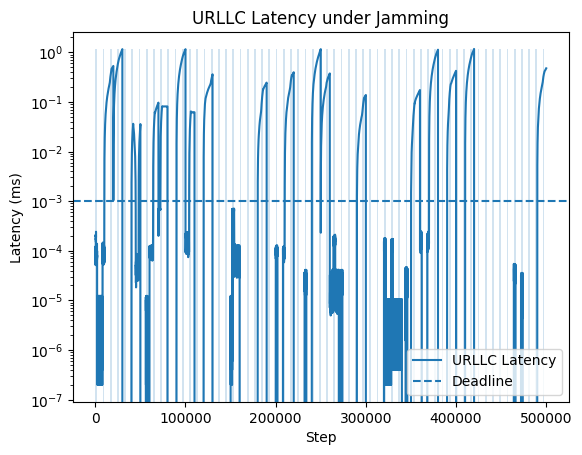

In [9]:
URLLC_DEADLINE = 0.001  # ms (set your real value)

plt.figure()
plt.plot(wide["step"], wide["latency/urllc"], label="URLLC Latency")
plt.axhline(URLLC_DEADLINE, linestyle="--", label="Deadline")

plt.fill_between(
    wide["step"],
    wide["latency/urllc"].min(),
    wide["latency/urllc"].max(),
    where=wide["jamming"],
    alpha=0.2
)

plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("Latency (ms)")
plt.legend()
plt.title("URLLC Latency under Jamming")
plt.show()
